## 1. Imports and settings


In [2]:
import os
import sys
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from tensorflow import keras 
from tensorflow.keras import layers 
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report, confusion_matrix,
    balanced_accuracy_score, f1_score
)

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
FINE_TUNE_LR = 1e-5

# Use image + age/sex/site metadata when available.
USE_METADATA = False  # image-only model; metadata is not used as input

# Training-only class balancing settings.
# `ak` and `akiec` are the same diagnosis, so `ak` is merged into `akiec` before training.
MERGE_LABELS = {"ak": "akiec"}
AUGMENT_CLASSES = {"akiec", "df", "scc", "vasc"}
UNDERSAMPLE_CLASS = "nv"
BALANCE_TO_LARGEST_NON_NV = True
AUTOTUNE = tf.data.AUTOTUNE

# ---- Environment (Kaggle / Colab / local) ----
IN_KAGGLE = Path("/kaggle/working").exists()
IN_COLAB = "google.colab" in sys.modules

# Colab-only options
SAVE_TO_DRIVE = False   # True: keep checkpoints/outputs on Google Drive so they survive a disconnect
DRIVE_DATA_DIR = None   # optional: dataset folder on Drive, e.g. "/content/drive/MyDrive/skin-data"
KAGGLE_DATASET = "beshoyshohdy/skin-data"   # owner/slug exactly as in the dataset's Kaggle URL
DATA_ZIP = None         # optional: zip of the dataset (e.g. "/content/drive/MyDrive/skin-data.zip"), extracted automatically

if IN_COLAB and (SAVE_TO_DRIVE or DRIVE_DATA_DIR or DATA_ZIP):
    from google.colab import drive
    drive.mount("/content/drive")

if IN_KAGGLE:
    WORK_DIR = Path("/kaggle/working")
elif IN_COLAB:
    WORK_DIR = Path("/content/drive/MyDrive/skin_outputs") if SAVE_TO_DRIVE else Path("/content/outputs")
else:
    WORK_DIR = Path("outputs")
WORK_DIR.mkdir(parents=True, exist_ok=True)
print("Environment:", "Kaggle" if IN_KAGGLE else "Colab" if IN_COLAB else "local", "| outputs ->", WORK_DIR)

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


Environment: Kaggle | outputs -> /kaggle/working
TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Find the dataset

Search order: (1) a Google Drive folder (`DRIVE_DATA_DIR`) or zip file (`DATA_ZIP`) if set, (2) `kagglehub` (uses the attached dataset on Kaggle, downloads it otherwise; on Colab it may ask you to log in to Kaggle), (3) anything attached under `/kaggle/input`.

If `kagglehub` reports **404 Not Found**, the dataset is private or not shared with the Kaggle account you logged in with. Use `DRIVE_DATA_DIR` / `DATA_ZIP` instead (see section 1).


In [3]:
try:
    import kagglehub
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub

HANDLE = KAGGLE_DATASET

# Colab: use Kaggle credentials stored in Colab Secrets (key icon, left sidebar) if they exist
if IN_COLAB:
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        print("Using Kaggle credentials from Colab Secrets.")
    except Exception:
        pass   # no secrets set: kagglehub will ask for a login if it needs one


def has_layout(folder):
    return (folder / "metadata.csv").is_file() and all(
        (folder / s).is_dir() for s in ("train", "val", "test")
    )


def download_with_kagglehub():
    try:
        return Path(kagglehub.dataset_download(HANDLE))
    except Exception as first_error:
        if not IN_COLAB:
            raise
        # Colab: ask for Kaggle credentials (or use the KAGGLE_USERNAME / KAGGLE_KEY Colab secrets) and retry
        print("Download failed:", first_error)
        print("Log in to Kaggle (username + API key from kaggle.com/settings) ...")
        kagglehub.login()
        return Path(kagglehub.dataset_download(HANDLE))


def find_data_root():
    # 0) dataset already on Google Drive
    if DRIVE_DATA_DIR:
        for csv in Path(DRIVE_DATA_DIR).rglob("metadata.csv"):
            if has_layout(csv.parent):
                return csv.parent
        print("DRIVE_DATA_DIR is set but no valid dataset folder was found in it.")

    # 0b) zip file (e.g. downloaded from Kaggle and uploaded to Drive)
    if DATA_ZIP:
        import shutil
        target = Path("/content/skin_data") if IN_COLAB else WORK_DIR / "skin_data"
        if not target.exists():
            print("Extracting", DATA_ZIP, "->", target)
            shutil.unpack_archive(str(DATA_ZIP), str(target))
        for csv in target.rglob("metadata.csv"):
            if has_layout(csv.parent):
                return csv.parent
        print("DATA_ZIP was extracted but no valid dataset folder (metadata.csv + train/val/test) was found in it.")

    # 1) kagglehub: uses the attached dataset on Kaggle, downloads it otherwise
    try:
        base = download_with_kagglehub()
        for csv in base.rglob("metadata.csv"):
            if has_layout(csv.parent):
                return csv.parent
    except Exception as e:
        print("kagglehub could not load the dataset:", e)

    # 2) fall back to anything attached under /kaggle/input
    for csv in Path("/kaggle/input").rglob("metadata.csv"):
        if has_layout(csv.parent):
            return csv.parent

    raise FileNotFoundError(
        "Could not find a folder with metadata.csv + train/val/test. "
        "Kaggle: + Add Input -> search 'skin data' (beshoyshohdy). "
        "Colab: a 404 from kagglehub means the dataset is private or not shared with the Kaggle account you logged in with. "
        "Set DRIVE_DATA_DIR (folder) or DATA_ZIP (zip file) in section 1 instead."
    )


DATA_ROOT = find_data_root()
print("Data root:", DATA_ROOT)
for s in ("train", "val", "test"):
    print(f"  {s}: {sum(1 for _ in os.scandir(DATA_ROOT / s))} files")


Data root: /kaggle/input/datasets/beshoyshohdy/skin-data/tensorflow_original/tensorflow_original
  train: 15374 files
  val: 3621 files
  test: 3657 files


## 3. Load `metadata.csv` and match every row to an image

`image_path` in the CSV still holds the **original** paths from the session that exported the data, so they don't exist here. The export copied each image to
`<split>/<diagnosis>_<original file name>`, so each row is matched to a file by that rule (ignoring upper/lower case and the file extension).

Some rows have no image file (the export skipped images it could not find). Those rows are **dropped**, listed in `rows_without_images.csv`, and counted per class. If more than `MAX_MISSING_FRACTION` of the rows are missing, the notebook stops, because that points to a naming problem rather than a few lost images.

In [4]:
meta = pd.read_csv(DATA_ROOT / "metadata.csv")
print("Rows in metadata.csv:", len(meta))
print("Columns:", meta.columns.tolist())

IMAGE_COL = "image_path"
LABEL_COL = "diagnosis"
AGE_COL = "age"
SEX_COL = "sex"
SITE_COL = "anatom_site_general_challenge"
FLAG_COLS = ["age_missing", "site_missing", "sex_missing"]
SPLITS = ("train", "val", "test")
MAX_MISSING_FRACTION = 0.05     # stop if more than 5% of rows have no image

required = [IMAGE_COL, LABEL_COL, "split"]
if USE_METADATA:
    required += [AGE_COL, SEX_COL, SITE_COL] + FLAG_COLS
missing_cols = [c for c in required if c not in meta.columns]
assert not missing_cols, f"metadata.csv is missing columns: {missing_cols}"

# Rows with no path / label / split can never be used
n_before = len(meta)
meta = meta.dropna(subset=[IMAGE_COL, LABEL_COL, "split"]).copy()
if len(meta) < n_before:
    print(f"Dropped {n_before - len(meta)} rows with an empty image_path, diagnosis or split.")

meta[LABEL_COL] = meta[LABEL_COL].astype(str).str.strip()
meta["split"] = meta["split"].astype(str).str.lower().str.strip()
assert set(meta["split"].unique()) == set(SPLITS), meta["split"].unique()

# ---- match every row to a real file ----
def base_name(path):
    return str(path).replace("\\", "/").split("/")[-1]


def stem_key(name):
    return Path(name).stem.lower()          # ignores case and extension


files_by_split = {s: os.listdir(DATA_ROOT / s) for s in SPLITS}
lookup = {s: {stem_key(f): f for f in files} for s, files in files_by_split.items()}

meta["original_path"] = meta[IMAGE_COL].astype(str)
wanted = meta[LABEL_COL] + "_" + meta["original_path"].map(base_name)
meta["_file"] = [lookup[s].get(stem_key(w)) for s, w in zip(meta["split"], wanted)]

has_file = meta["_file"].notna()
n_missing = int((~has_file).sum())

if n_missing:
    lost = meta.loc[~has_file, ["original_path", "split", LABEL_COL]]
    lost.to_csv(WORK_DIR / "rows_without_images.csv", index=False)

    print(f"\n{n_missing} rows ({n_missing / len(meta):.2%}) have no image file and will be dropped.")
    print("Saved the list to", WORK_DIR / "rows_without_images.csv")
    print("\nDropped rows per class and split:")
    print(pd.crosstab(lost[LABEL_COL], lost["split"]).reindex(columns=list(SPLITS), fill_value=0))
    print("\nExample expected file names:", wanted[~has_file].head(3).tolist())

    assert n_missing / len(meta) <= MAX_MISSING_FRACTION, (
        f"More than {MAX_MISSING_FRACTION:.0%} of the rows have no image. "
        "That looks like a naming mismatch, not a few lost files. "
        "Compare the expected names above with the real file names in train/."
    )
else:
    print("\nEvery row has an image file.")

meta = meta[has_file].copy()
assert len(meta) > 0, "No images matched. Check the file naming rule above."

meta[IMAGE_COL] = [str(DATA_ROOT / s / f) for s, f in zip(meta["split"], meta["_file"])]
meta = meta.drop(columns="_file")

# Two rows can point to the same file: keep one
n_dup = int(meta.duplicated(subset=[IMAGE_COL]).sum())
if n_dup:
    print(f"\nDropped {n_dup} rows that point to an image already used by another row.")
    meta = meta.drop_duplicates(subset=[IMAGE_COL])
meta = meta.reset_index(drop=True)

# Image files that no row refers to (just reported, never used)
used = set(zip(meta["split"], meta[IMAGE_COL].map(lambda p: Path(p).name)))
orphans = {s: sum(1 for f in files_by_split[s] if (s, f) not in used) for s in SPLITS}
if any(orphans.values()):
    print("\nImage files with no row in the CSV (ignored):", orphans)

print("\nRows kept:", len(meta), "of", n_before)
print(meta["split"].value_counts().to_string())

Rows in metadata.csv: 24930
Columns: ['image_path', 'diagnosis', 'source', 'sha256', 'lesion_id', 'group_id', 'age', 'sex', 'anatom_site_general_challenge', 'split', 'age_missing', 'site_missing', 'sex_missing', 'label']

Every row has an image file.

Dropped 2278 rows that point to an image already used by another row.

Rows kept: 22652 of 24930
split
train    15374
test      3657
val       3621


## 4. Labels, splits, and training-only class balancing

The labels `ak` and `akiec` are first merged into one class (`akiec`). The four specified minority classes are oversampled to the largest non-`nv` class count. `nv` is undersampled to that same count. Only training rows are resampled; validation and test sets remain untouched.


In [5]:
# ---- merge duplicate class names: `ak` and `akiec` are the same diagnosis ----
# Done here, AFTER the image files were matched in section 3 (those file names contain the original label).
print("Class counts before merge:")
print(meta[LABEL_COL].value_counts().sort_index().to_string())

meta[LABEL_COL] = meta[LABEL_COL].replace(MERGE_LABELS)
assert not (set(MERGE_LABELS) & set(meta[LABEL_COL].unique())), "Merge failed: an old label is still present."

print(f"\nAfter merging {MERGE_LABELS}:")
print(meta[LABEL_COL].value_counts().sort_index().to_string())
print()

class_names = sorted(meta[LABEL_COL].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for name, i in class_to_idx.items()}
NUM_CLASSES = len(class_names)

meta["label"] = meta[LABEL_COL].map(class_to_idx).astype("int32")

train_df = meta[meta["split"] == "train"].reset_index(drop=True)
val_df = meta[meta["split"] == "val"].reset_index(drop=True)
test_df = meta[meta["split"] == "test"].reset_index(drop=True)

# ---- partially rebalance TRAINING rows only (classes stay unequal) ----
MINORITY_FRACTION = 0.5   # minority classes are raised to 50% of the reference count
NV_CAP_MULTIPLIER = 2.0   # nv is capped at 2x the reference count
MAX_UPSAMPLE_FACTOR = 5   # optional: never repeat a class more than 5x its original size

original_train_counts = train_df[LABEL_COL].value_counts().sort_index()
non_nv_counts = original_train_counts.drop(labels=[UNDERSAMPLE_CLASS], errors="ignore")
assert len(non_nv_counts) > 0, "No non-nv classes found in the training split."

REF_COUNT = int(non_nv_counts.max())              # largest non-nv class
MINORITY_TARGET = int(REF_COUNT * MINORITY_FRACTION)
NV_TARGET = int(REF_COUNT * NV_CAP_MULTIPLIER)

print("Original training counts:")
print(original_train_counts.to_string())
print(f"\nReference: {REF_COUNT} | minority floor: {MINORITY_TARGET} | nv cap: {NV_TARGET}")

parts = []
for class_name, group in train_df.groupby(LABEL_COL, sort=False):
    group = group.reset_index(drop=True)
    n_orig = len(group)

    if class_name in AUGMENT_CLASSES:
        # Raise small classes toward the floor, but never above it and never
        # beyond MAX_UPSAMPLE_FACTOR x the original size.
        target = min(MINORITY_TARGET, n_orig * MAX_UPSAMPLE_FACTOR)
        if n_orig < target:
            extra = group.sample(n=target - n_orig, replace=True, random_state=SEED)
            group = pd.concat([group, extra], ignore_index=True)
            print(f"Upsampled {class_name}: {n_orig} -> {len(group)} rows")

    elif class_name == UNDERSAMPLE_CLASS:
        # Only trim the dominant class down to the cap
        if n_orig > NV_TARGET:
            group = group.sample(n=NV_TARGET, replace=False, random_state=SEED).reset_index(drop=True)
        print(f"Undersampled {class_name}: {n_orig} -> {len(group)} rows")

    parts.append(group)

train_df = (pd.concat(parts, ignore_index=True)
            .sample(frac=1.0, random_state=SEED)
            .reset_index(drop=True))

print("\nTraining counts after resampling:")
print(train_df[LABEL_COL].value_counts().sort_index().to_string())

print("Classes:", class_to_idx)
print("\nImages per class and split (what the model will actually use):")
used_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
print(pd.crosstab(used_df[LABEL_COL], used_df["split"])[["train", "val", "test"]])

# No lesion/image group may appear in more than one split
if "group_id" in meta.columns:
    leaks = (meta.groupby("group_id")["split"].nunique() > 1).sum()
    print("\nGroups present in more than one split:", leaks)
    assert leaks == 0, "Leakage: the same lesion appears in several splits."

# Class weights from the training split only
train_classes = set(train_df["label"].unique())
assert train_classes == set(range(NUM_CLASSES)), "Some class has no training images."

weights = compute_class_weight(
    "balanced", classes=np.arange(NUM_CLASSES), y=train_df["label"].to_numpy()
)
# Soften the weights: sqrt keeps the direction but reduces the strength,
# so resampling and weighting don't both fully correct the imbalance.
weights = np.sqrt(weights)
class_weights = {i: float(w) for i, w in enumerate(weights)}
print("\nClass weights:", {idx_to_class[i]: round(w, 2) for i, w in class_weights.items()})

Class counts before merge:
diagnosis
ak        859
akiec     327
bcc      3579
bkl      3123
df        304
mel      5001
nv       8516
scc       628
vasc      315

After merging {'ak': 'akiec'}:
diagnosis
akiec    1186
bcc      3579
bkl      3123
df        304
mel      5001
nv       8516
scc       628
vasc      315

Original training counts:
diagnosis
akiec     830
bcc      2382
bkl      2066
df        194
mel      3419
nv       5829
scc       448
vasc      206

Reference: 3419 | minority floor: 1709 | nv cap: 6838
Upsampled vasc: 206 -> 1030 rows
Upsampled df: 194 -> 970 rows
Upsampled scc: 448 -> 1709 rows
Upsampled akiec: 830 -> 1709 rows
Undersampled nv: 5829 -> 5829 rows

Training counts after resampling:
diagnosis
akiec    1709
bcc      2382
bkl      2066
df        970
mel      3419
nv       5829
scc      1709
vasc     1030
Classes: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'scc': 6, 'vasc': 7}

Images per class and split (what the model will actually use):
spl

## 5. Metadata is not used as model input

This image-only version does not encode or use age, sex, anatomical site, or missingness flags as model features.

In [6]:
# Intentionally no metadata feature encoding in this notebook.
# metadata.csv is used only for image paths, diagnosis labels, and split names.
def encode_meta(d):
    n = len(d)
    return (np.zeros((n, 1), "float32"),
            np.zeros(n, "int32"), np.zeros(n, "int32"))


## 6. Build TensorFlow datasets

Images are resized with padding and preprocessed for DenseNet121. During training only, `akiec`, `df`, `scc`, and `vasc` receive random flips, rotations, zoom/translation, and mild contrast/brightness changes. Validation and test images are not augmented.


In [7]:
# DenseNet121 preprocess_input expects RGB pixels in the 0-255 range.
from tensorflow.keras.applications.densenet import preprocess_input

AUGMENT_LABEL_IDS = tf.constant(
    [class_to_idx[c] for c in AUGMENT_CLASSES if c in class_to_idx], dtype=tf.int32
)

@tf.function
def augment_image(image):
    # image is RGB float32 in [0, 255], before DenseNet preprocessing.
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.rot90(image, k=tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32))
    image = tf.image.random_brightness(image, max_delta=12.0)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image

def load_sample(path, num, sex, site, label, training=False):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(image, IMG_SIZE, IMG_SIZE, method="bilinear")
    image = tf.cast(image, tf.float32)

    if training:
        should_augment = tf.reduce_any(tf.equal(label, AUGMENT_LABEL_IDS))
        image = tf.cond(should_augment, lambda: augment_image(image), lambda: image)

    image = preprocess_input(image)
    # Only image pixels enter the model. Metadata placeholders are ignored.
    return {"image": image}, label

def make_ds(dataframe, training=False):
    num, sex, site = encode_meta(dataframe)
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe[IMAGE_COL].to_numpy(), num, sex, site,
        dataframe["label"].to_numpy(dtype=np.int32)
    ))
    if training:
        ds = ds.shuffle(min(len(dataframe), 5000), seed=SEED,
                        reshuffle_each_iteration=True)
        ds = ds.map(lambda p, n, s, t, y: load_sample(p, n, s, t, y, training=True),
                    num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda p, n, s, t, y: load_sample(p, n, s, t, y, training=False),
                    num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

inputs_batch, labels_batch = next(iter(train_ds))
for k, v in inputs_batch.items():
    print(f"{k:6s}", v.shape, v.dtype.name)
print("labels", labels_batch.shape)


I0000 00:00:1793241138.154660      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793241138.158815      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


image  (16, 224, 224, 3) float32
labels (16,)


## 7. Build pretrained DenseNet121 image-only model
The image backbone starts with ImageNet weights and is frozen for the first training stage. Then the top part is unfrozen for low-learning-rate fine-tuning.

In [8]:
def build_model():
    img_in = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")

    backbone = keras.applications.DenseNet201(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
        pooling="avg"
    )
    backbone.trainable = False
    x = backbone(img_in, training=False)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    

    z = x

    z = layers.Dense(256, activation="relu")(z)
    z = layers.Dropout(0.35)(z)
    z = layers.Dense(128, activation="relu")(z)
    z = layers.Dense(64, activation="relu")(z)
    z = layers.Dropout(0.35)(z)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(z)
    model = keras.Model({"image": img_in}, outputs, name="skin_densenet201_image_only")
    return model, backbone

model, backbone = build_model()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()


74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "skin_densenet201_image_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet201 (Functional)        │ (None, 1920)           │    18,321,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1920)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       491,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,921,224 (72.18 MB)

 Trainable params: 599,240 (2.29 MB)

 Non-trainable params: 18,321,984 (69.89 MB)

## 8. Train the classifier head


In [9]:
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"].to_numpy()
)
class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(np.unique(train_df["label"]), class_weights_array)
}
print("Class weights:", class_weights)

checkpoint_path = WORK_DIR / "best_densenet121.keras"
callbacks = [
    keras.callbacks.ModelCheckpoint(
        str(checkpoint_path), monitor="val_loss",
        save_best_only=True, verbose=0
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=0
    ),
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Class weights: {0: 1.3980397893504974, 1: 1.0030436607892528, 2: 1.1564617618586641, 3: 2.4631443298969073, 4: 0.698815443112021, 5: 0.4098902041516555, 6: 1.3980397893504974, 7: 2.3196601941747574}
Epoch 1/10
   1/1195 ━━━━━━━━━━━━━━━━━━━━ 18:09:03 55s/step - accuracy: 0.1250 - loss: 2.5809

I0000 00:00:1793241202.335836     143 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1195/1195 ━━━━━━━━━━━━━━━━━━━━ 492s 367ms/step - accuracy: 0.4469 - loss: 1.5819 - val_accuracy: 0.5338 - val_loss: 1.3459 - learning_rate: 0.0010
Epoch 2/10
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 106s 89ms/step - accuracy: 0.5500 - loss: 1.2957 - val_accuracy: 0.5982 - val_loss: 1.1148 - learning_rate: 0.0010
Epoch 3/10
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 106s 89ms/step - accuracy: 0.5876 - loss: 1.1656 - val_accuracy: 0.6352 - val_loss: 0.9873 - learning_rate: 0.0010
Epoch 4/10
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 103s 86ms/step - accuracy: 0.6114 - loss: 1.0822 - val_accuracy: 0.6067 - val_loss: 1.0538 - learning_rate: 0.0010
Epoch 5/10
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 103s 86ms/step - accuracy: 0.6244 - loss: 1.0384 - val_accuracy: 0.6230 - val_loss: 0.9898 - learning_rate: 0.0010
Epoch 6/10
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 106s 88ms/step - accuracy: 0.6608 - loss: 0.9316 - val_accuracy: 0.6393 - val_loss: 0.9490 - learning_rate: 5.0000e-04
Epoch 7/10
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 107s 89ms/step - accur

## 9. Fine-tune the top of DenseNet201


In [11]:
# Unfreeze the top ~20% of the backbone; keep BatchNormalization frozen.
backbone.trainable = True
fine_tune_from = int(len(backbone.layers) * 0.80)
for layer in backbone.layers[:fine_tune_from]:
    layer.trainable = False
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks
)

# Load the best validation-loss checkpoint from either training stage.
if checkpoint_path.exists():
    model = keras.models.load_model(checkpoint_path)
    print("Loaded best checkpoint:", checkpoint_path)


Epoch 1/8
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 262s 167ms/step - accuracy: 0.7053 - loss: 0.7679 - val_accuracy: 0.6700 - val_loss: 0.8641 - learning_rate: 1.0000e-05
Epoch 2/8
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 121s 101ms/step - accuracy: 0.7194 - loss: 0.7110 - val_accuracy: 0.6667 - val_loss: 0.8610 - learning_rate: 1.0000e-05
Epoch 3/8
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 121s 101ms/step - accuracy: 0.7373 - loss: 0.6691 - val_accuracy: 0.6827 - val_loss: 0.8277 - learning_rate: 1.0000e-05
Epoch 4/8
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 122s 102ms/step - accuracy: 0.7474 - loss: 0.6449 - val_accuracy: 0.6896 - val_loss: 0.8190 - learning_rate: 1.0000e-05
Epoch 5/8
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 121s 101ms/step - accuracy: 0.7568 - loss: 0.6083 - val_accuracy: 0.6965 - val_loss: 0.8155 - learning_rate: 1.0000e-05
Epoch 6/8
1195/1195 ━━━━━━━━━━━━━━━━━━━━ 122s 102ms/step - accuracy: 0.7659 - loss: 0.5837 - val_accuracy: 0.6926 - val_loss: 0.8138 - learning_rate: 1.0000e-05
Epoch 7/8
1195/1195 ━━━━━━━━━━━━━━

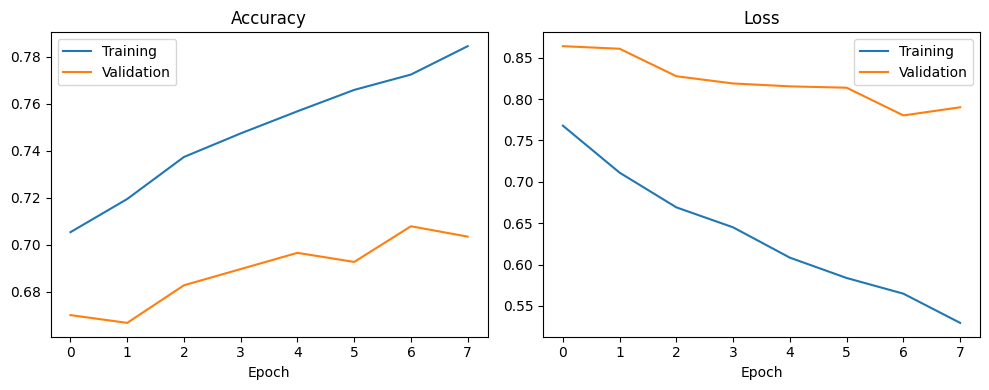

In [12]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_fine.history["accuracy"], label="Training")
plt.plot(history_fine.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_fine.history["loss"], label="Training")
plt.plot(history_fine.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

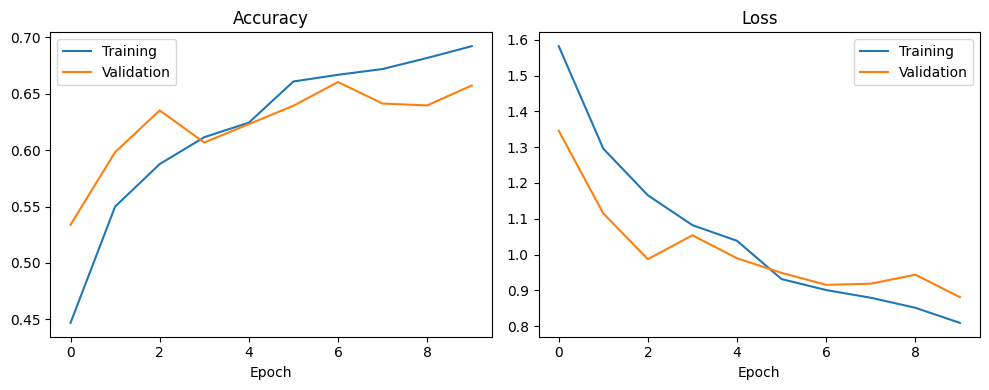

In [13]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history_head.history["accuracy"], label="Training")
plt.plot(history_head.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_head.history["loss"], label="Training")
plt.plot(history_head.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Evaluate on the held-out test set


229/229 ━━━━━━━━━━━━━━━━━━━━ 136s 487ms/step
Accuracy:          0.7099
Balanced accuracy: 0.659
Macro F1:          0.6538

              precision    recall  f1-score   support

       akiec       0.40      0.43      0.41       182
         bcc       0.67      0.82      0.73       593
         bkl       0.54      0.62      0.58       530
          df       0.70      0.61      0.65        46
         mel       0.70      0.62      0.66       802
          nv       0.89      0.80      0.84      1348
         scc       0.47      0.47      0.47        95
        vasc       0.86      0.90      0.88        61

    accuracy                           0.71      3657
   macro avg       0.65      0.66      0.65      3657
weighted avg       0.72      0.71      0.71      3657



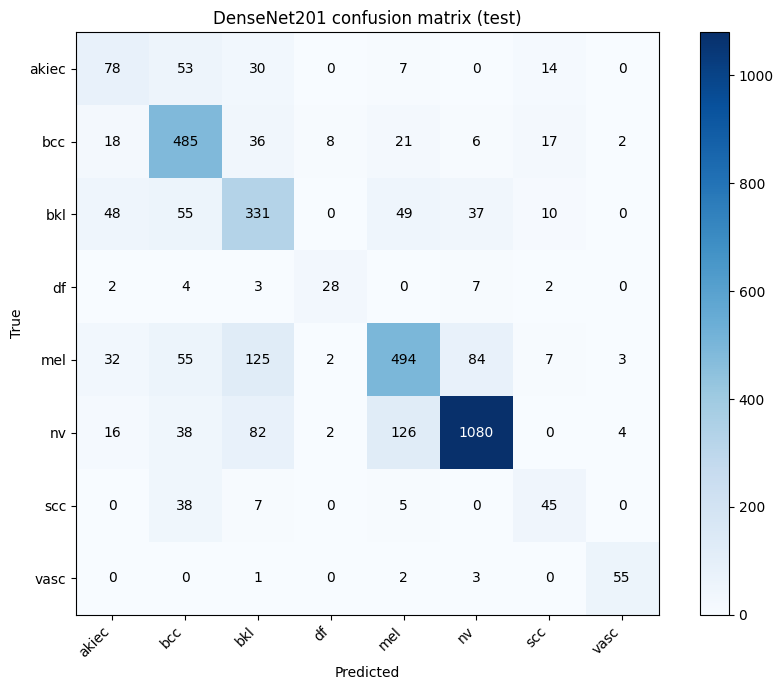

In [14]:
y_true = test_df["label"].to_numpy()
y_prob = model.predict(test_ds)
y_pred = y_prob.argmax(axis=1)

assert len(y_true) == len(y_pred), "Prediction count does not match test rows."
print("Accuracy:         ", round((y_true == y_pred).mean(), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))
print("Macro F1:         ", round(f1_score(y_true, y_pred, average="macro"), 4))
print()
print(classification_report(
    y_true, y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(9, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(NUM_CLASSES), class_names, rotation=45, ha="right")
plt.yticks(range(NUM_CLASSES), class_names)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("DenseNet201 confusion matrix (test)")
plt.tight_layout()
plt.show()
